# 🎯 Analyse de Sentiment — Darija Marocaine
## Étapes 4 & 5 : Entraînement, Évaluation & Suivi Expérimental
### Dataset : ~80 000 commentaires YouTube/Instagram annotés (positif / négatif / neutre)

In [ ]:
# Fix numpy en premier (cause principale du problème)
!pip install -q "numpy>=2.0" --upgrade

# Restart automatique du kernel après numpy
import os
os.kill(os.getpid(), 9)

In [1]:
!pip install -q wandb lightgbm xgboost scikit-learn datasets accelerate

# transformers version spécifique compatible avec unsloth
!pip install -q "transformers==4.51.3"

!pip install -q unsloth

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
trl 0.24.0 requires transformers>=4.56.1, but you have transformers 4.51.3 which is incompatible.


verification des biblio 

In [2]:
import numpy as np
print(f"✅ numpy : {np.__version__}")

import lightgbm as lgb
print(f"✅ lightgbm : {lgb.__version__}")

import wandb
print(f"✅ wandb : {wandb.__version__}")

import transformers
print(f"✅ transformers : {transformers.__version__}")

import sklearn
print(f"✅ sklearn : {sklearn.__version__}")

print("\n🎉 Tout est prêt !")

✅ numpy : 2.4.4
✅ lightgbm : 4.6.0
✅ wandb : 0.25.0
✅ transformers : 5.5.0
✅ sklearn : 1.6.1

🎉 Tout est prêt !


## 📦 1. Imports & Configuration

In [3]:
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Sklearn — Preprocessing & Split
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline

# Sklearn — Features
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Sklearn — Modèles classiques
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# Sklearn — Métriques
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# LightGBM & XGBoost
import lightgbm as lgb
import xgboost as xgb

# Sauvegarde des modèles
import joblib

# W&B — Tracking expérimental
import wandb

# Reproductibilité
warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ Tous les imports sont chargés avec succès")

✅ Tous les imports sont chargés avec succès


## 🔗 2. Configuration de Weights & Biases

In [4]:
from kaggle_secrets import UserSecretsClient

# Récupération de la clé API depuis les secrets Kaggle
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")
wandb.login(key=wandb_api_key)

# Configuration du projet W&B
WANDB_PROJECT = "darija-sentiment-analysis"
WANDB_ENTITY = None  # Laisse None si compte personnel, sinon mets ton username W&B

print(f"✅ Connecté à W&B — Projet : {WANDB_PROJECT}")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ihssanfoudal (ihssanfoudal-ensa) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


✅ Connecté à W&B — Projet : darija-sentiment-analysis


## 📂 Chargement & Vérification du Dataset
Le dataset contient ~80 000 commentaires YouTube/Instagram annotés en Darija marocaine.
Chaque commentaire possède les champs : `comment_id`, `text_clean`, `sentiment`.

# **CELLULE 8 — Code : Chargement du JSON**

In [5]:
# ⚠️ Modifie ce chemin selon le nom exact de ton fichier uploadé sur Kaggle
DATA_PATH = "/kaggle/input/datasets/ihsanihsanihsan/datasetp/totaldata.json"

# Chargement du fichier JSON
with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

# Conversion en DataFrame
df = pd.DataFrame(data)

print(f"✅ Dataset chargé : {len(df)} commentaires")
print(f"\n📊 Colonnes disponibles : {list(df.columns)}")
print(f"\n🔍 Aperçu des premières lignes :")
df.head()

✅ Dataset chargé : 83411 commentaires

📊 Colonnes disponibles : ['comment_id', 'text_clean', 'sentiment']

🔍 Aperçu des premières lignes :


,comment_id,text_clean,sentiment
0,UgwodTeGOvTeIGNux8Z4AaABAg,مقرلتيناش كيفاش مديرو مليون دولار,neutre
1,Ugw9ANN-50l1Di_FLQp4AaABAg,lah y barek concept nadi kat wa33i shabab,positif
2,UgynNafjO6kDQRemBZ14AaABAg,الموضوع كيف تتحرر من وسايل التواصل الاجتماعي,neutre
3,UgzmAQ1zH4yG2_-enKJ4AaABAg,فاش شفت السطوري و الترويج قلت غا تكون شي حاجه ...,positif
4,UgzwHC0zOu9rFQPvtBt4AaABAg,رياله وصلات خويا سيمو,neutre


# **CELLULE 9 — Code : Vérification et nettoyage**

📋 INFORMATIONS GÉNÉRALES (AVANT NETTOYAGE)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83411 entries, 0 to 83410
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   comment_id  83411 non-null  object
 1   text_clean  83411 non-null  object
 2   sentiment   83411 non-null  object
dtypes: object(3)
memory usage: 1.9+ MB
None

🔍 AUDIT DES ANOMALIES (VALEURS NULLES & DOUBLONS)
Valeurs manquantes par colonne :
comment_id    0
text_clean    0
sentiment     0
dtype: int64
Commentaires vides (uniquement des espaces) : 0
Commentaires dupliqués détectés : 29

🧹 NETTOYAGE EN COURS...
Total des lignes supprimées : 29
✅ Dataset final prêt pour l'entraînement : 83382 commentaires restants

📊 DISTRIBUTION FINALE DES CLASSES
sentiment
positif    28602
negatif    27825
neutre     26955
Name: count, dtype: int64

Pourcentages finaux :
sentiment
positif    34.30
negatif    33.37
neutre     32.33
Name: count, dtype: float64


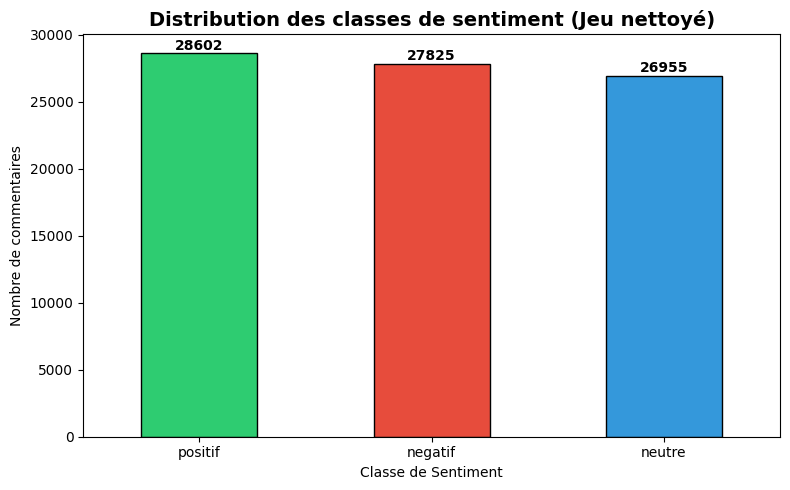

✅ Graphique sauvegardé sous 'distribution_classes_nettoye.png'


In [6]:
import matplotlib.pyplot as plt

# --- Vérification de la structure ---
print("=" * 50)
print("📋 INFORMATIONS GÉNÉRALES (AVANT NETTOYAGE)")
print("=" * 50)
print(df.info())

taille_initiale = len(df)

# --- Audit des anomalies ---
print("\n" + "=" * 50)
print("🔍 AUDIT DES ANOMALIES (VALEURS NULLES & DOUBLONS)")
print("=" * 50)

# 1. Vérification des valeurs manquantes (NaN)
valeurs_nulles = df.isnull().sum()
print("Valeurs manquantes par colonne :")
print(valeurs_nulles)

# 2. Vérification des textes vides (espaces invisibles)
textes_vides = (df['text_clean'].astype(str).str.strip() == '').sum()
print(f"Commentaires vides (uniquement des espaces) : {textes_vides}")

# 3. Vérification des doublons stricts
doublons = df.duplicated(subset=['text_clean']).sum()
print(f"Commentaires dupliqués détectés : {doublons}")

# --- Nettoyage ---
print("\n" + "=" * 50)
print("🧹 NETTOYAGE EN COURS...")
print("=" * 50)

# Suppression des lignes avec text_clean ou sentiment manquant
df = df.dropna(subset=['text_clean', 'sentiment'])
# Suppression des textes vides
df = df[df['text_clean'].astype(str).str.strip() != '']
# Suppression des doublons (on garde la première occurrence)
df = df.drop_duplicates(subset=['text_clean'])

lignes_supprimees = taille_initiale - len(df)
print(f"Total des lignes supprimées : {lignes_supprimees}")
print(f"✅ Dataset final prêt pour l'entraînement : {len(df)} commentaires restants")


# --- Distribution Finale (Après Nettoyage) ---
print("\n" + "=" * 50)
print("📊 DISTRIBUTION FINALE DES CLASSES")
print("=" * 50)
class_counts = df['sentiment'].value_counts()
print(class_counts)
print(f"\nPourcentages finaux :")
print((class_counts / len(df) * 100).round(2)) # .round(2) pour un affichage plus propre

# --- Visualisation ---
plt.figure(figsize=(8, 5))

# Création d'un dictionnaire de couleurs pour que chaque classe ait toujours la même couleur
couleurs_dict = {'positif': '#2ecc71', 'negatif': '#e74c3c', 'neutre': '#3498db'}
# Appliquer les couleurs en fonction de l'index réel de la série
couleurs_barres = [couleurs_dict.get(x.lower(), '#95a5a6') for x in class_counts.index]

class_counts.plot(kind='bar', color=couleurs_barres, edgecolor='black')
plt.title("Distribution des classes de sentiment (Jeu nettoyé)", fontsize=14, fontweight='bold')
plt.xlabel("Classe de Sentiment")
plt.ylabel("Nombre de commentaires")
plt.xticks(rotation=0)

# Ajout des valeurs au-dessus des barres
for i, v in enumerate(class_counts):
    plt.text(i, v + (v * 0.01), str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("distribution_classes_nettoye.png", dpi=150)
plt.show()
print("✅ Graphique sauvegardé sous 'distribution_classes_nettoye.png'")

## ✂️ 4. Split Stratifié : Train / Validation / Test

In [7]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from collections import Counter
from sklearn.preprocessing import LabelEncoder

# Encodage des labels
le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])

# Affichage du mapping
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"📌 Mapping des labels : {label_mapping}")

# Création d'un tableau d'indices explicite pour éviter le bug de np.where
X = df['text_clean'].values
y = df['label'].values
indices = np.arange(len(df)) # [0, 1, 2, ... taille_totale]

# Split : 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X, y, indices, test_size=0.30, random_state=SEED, stratify=y
)

X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"\n✅ Split réalisé :")
print(f"   Train      : {len(X_train)} exemples ({len(X_train)/len(X)*100:.1f}%)")
print(f"   Validation : {len(X_val)} exemples ({len(X_val)/len(X)*100:.1f}%)")
print(f"   Test       : {len(X_test)} exemples ({len(X_test)/len(X)*100:.1f}%)")

# =========================================================
# 🔍 VÉRIFICATION DE LA STRATIFICATION (POURCENTAGES)
# =========================================================
print("\n" + "=" * 60)
print("📊 PREUVE DE LA STRATIFICATION (POURCENTAGE PAR CLASSE)")
print("=" * 60)

# Fonction pour calculer les pourcentages
def get_class_percentages(y_array):
    counts = Counter(y_array)
    total = len(y_array)
    return {le.classes_[k]: (v / total * 100) for k, v in counts.items()}

# Calcul pour chaque sous-ensemble
dist_global = get_class_percentages(y)
dist_train = get_class_percentages(y_train)
dist_val = get_class_percentages(y_val)
dist_test = get_class_percentages(y_test)

# Création d'un tableau Pandas pour afficher ça de façon très propre
df_strat = pd.DataFrame({
    'Global (%)': dist_global,
    'Train (%)': dist_train,
    'Validation (%)': dist_val,
    'Test (%)': dist_test
}).round(2)

print(df_strat)
print("-" * 60)
print("💡 Si les pourcentages sont identiques horizontalement, la stratification est PARFAITE.")

# =========================================================
# SAUVEGARDE DES INDICES (CORRIGÉE)
# =========================================================
np.save("train_indices.npy", idx_train)
np.save("val_indices.npy", idx_val)
np.save("test_indices.npy", idx_test)
print("\n✅ Indices de Train, Val et Test sauvegardés pour reproductibilité.")

📌 Mapping des labels : {'negatif': np.int64(0), 'neutre': np.int64(1), 'positif': np.int64(2)}

✅ Split réalisé :
   Train      : 58367 exemples (70.0%)
   Validation : 12507 exemples (15.0%)
   Test       : 12508 exemples (15.0%)

📊 PREUVE DE LA STRATIFICATION (POURCENTAGE PAR CLASSE)
         Global (%)  Train (%)  Validation (%)  Test (%)
neutre        32.33      32.33           32.33     32.32
positif       34.30      34.30           34.30     34.31
negatif       33.37      33.37           33.37     33.37
------------------------------------------------------------
💡 Si les pourcentages sont identiques horizontalement, la stratification est PARFAITE.

✅ Indices de Train, Val et Test sauvegardés pour reproductibilité.


## 🔤 Représentations Textuelles (Features)

Trois types de features sont construits et comparés :

| Type | Description | Avantage |
|------|-------------|----------|
| **BoW** | Comptage des occurrences de mots | Simple, rapide, baseline |
| **TF-IDF** | Fréquence pondérée par rareté | Meilleur que BoW en général |
| **FastText** | Vecteurs denses 300D | Gère les mots inconnus en Darija |

 BoW et TF-IDF

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import joblib

# ---- BAG OF WORDS ----
print("🔨 Construction Bag of Words...")
bow_vec = CountVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    analyzer='word'
)
X_train_bow  = bow_vec.fit_transform(X_train)
X_val_bow    = bow_vec.transform(X_val)
X_test_bow   = bow_vec.transform(X_test)
joblib.dump(bow_vec, "bow_vectorizer.joblib")
print(f"✅ BoW : {X_train_bow.shape}")

# ---- TF-IDF ----
print("🔨 Construction TF-IDF...")
tfidf_vec = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)
X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_val_tfidf   = tfidf_vec.transform(X_val)
X_test_tfidf  = tfidf_vec.transform(X_test)
joblib.dump(tfidf_vec, "tfidf_vectorizer.joblib")
print(f"✅ TF-IDF : {X_train_tfidf.shape}")

print("\n✅ BoW et TF-IDF créés et sauvegardés")

🔨 Construction Bag of Words...
✅ BoW : (58367, 20000)
🔨 Construction TF-IDF...
✅ TF-IDF : (58367, 20000)

✅ BoW et TF-IDF créés et sauvegardés


verification avec qlq exemples

In [11]:
import random

print("="*60)
print("👁️ VÉRIFICATION SUR 3 COMMENTAIRES ALÉATOIRES")
print("="*60)

# 🟢 LA LIGNE MAGIQUE MANQUANTE : On extrait le dictionnaire des mots appris par le modèle
mots_appris = tfidf_vec.get_feature_names_out()

# On pioche 3 indices (numéros de lignes) au hasard dans le Train
indices_au_hasard = random.sample(range(len(X_train)), 3)

for i, index_test in enumerate(indices_au_hasard):
    commentaire_original = X_train[index_test]
    vecteur_bow = X_train_bow[index_test]
    vecteur_tfidf = X_train_tfidf[index_test]

    print(f"\n🟢 EXEMPLE {i+1} (Ligne {index_test})")
    print(f"📝 Texte : '{commentaire_original}'\n")

    # On récupère les mots qui existent dans ce commentaire
    indices_non_nuls = vecteur_bow.nonzero()[1]
    
    # On trie les mots par leur score TF-IDF (du plus important au moins important)
    mots_avec_scores = []
    for idx in indices_non_nuls:
        mots_avec_scores.append((
            mots_appris[idx],           # Le mot
            vecteur_bow[0, idx],        # Son compte BoW
            vecteur_tfidf[0, idx]       # Son poids TF-IDF
        ))
    
    # Tri décroissant selon le TF-IDF
    mots_avec_scores.sort(key=lambda x: x[2], reverse=True)

    print(f"{'TERME (Trié par importance)':<30} | {'BoW':<5} | {'TF-IDF'}")
    print("-" * 55)
    
    # On affiche les résultats (limité aux 10 mots les plus importants)
    for mot, compte, poids in mots_avec_scores[:10]:
        print(f"{mot:<30} | {compte:<5} | {poids:.4f}")
    print("-" * 55)

👁️ VÉRIFICATION SUR 3 COMMENTAIRES ALÉATOIRES

🟢 EXEMPLE 1 (Ligne 14628)
📝 Texte : 'مشكل نفسي و بالعقيده يتخبط بين المنقولات و المعقولات'

TERME (Trié par importance)    | BoW   | TF-IDF
-------------------------------------------------------
نفسي                           | 1     | 0.6184
بين                            | 1     | 0.5593
مشكل                           | 1     | 0.5521
-------------------------------------------------------

🟢 EXEMPLE 2 (Ligne 9144)
📝 Texte : 'سكت الهركاوي فالك شطاين عالم عنطيز'

TERME (Trié par importance)    | BoW   | TF-IDF
-------------------------------------------------------
الهركاوي                       | 1     | 0.6194
سكت                            | 1     | 0.5904
عالم                           | 1     | 0.5175
-------------------------------------------------------

🟢 EXEMPLE 3 (Ligne 48265)
📝 Texte : 'تفرجت نص ف2025 ونص لاخر'

TERME (Trié par importance)    | BoW   | TF-IDF
-------------------------------------------------------
ونص        

FastText Embeddings

In [12]:
import fasttext
import fasttext.util
import numpy as np
import os

print("🔨 Téléchargement modèle FastText arabe (300D) via wget...")
# Téléchargement forcé et robuste via la ligne de commande
if not os.path.exists('cc.ar.300.bin'):
    !wget https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ar.300.bin.gz
    !gunzip cc.ar.300.bin.gz

print("🔨 Chargement du modèle en mémoire (ça prend 1 à 2 minutes)...")
ft_model = fasttext.load_model('cc.ar.300.bin')
print(f"✅ FastText chargé — dim={ft_model.get_dimension()}")

def to_embedding(text, model):
    words = str(text).split()
    if not words:
        return np.zeros(model.get_dimension())
    return np.mean([model.get_word_vector(w) for w in words], axis=0)

print("🔨 Génération embeddings train...")
X_train_emb = np.array([to_embedding(t, ft_model) for t in X_train])
print("🔨 Génération embeddings val...")
X_val_emb   = np.array([to_embedding(t, ft_model) for t in X_val])
print("🔨 Génération embeddings test...")
X_test_emb  = np.array([to_embedding(t, ft_model) for t in X_test])

np.save("X_train_emb.npy", X_train_emb)
np.save("X_val_emb.npy",   X_val_emb)
np.save("X_test_emb.npy",  X_test_emb)
print(f"✅ Embeddings : {X_train_emb.shape} — sauvegardés")

🔨 Téléchargement modèle FastText arabe (300D) via wget...
🔨 Chargement du modèle en mémoire (ça prend 1 à 2 minutes)...
✅ FastText chargé — dim=300
🔨 Génération embeddings train...
🔨 Génération embeddings val...
🔨 Génération embeddings test...
✅ Embeddings : (58367, 300) — sauvegardés


verification

In [13]:
import random
import numpy as np

print("="*60)
print("👁️ VÉRIFICATION D'UN EMBEDDING (FASTTEXT)")
print("="*60)

# Prendre un commentaire au hasard dans le jeu d'entraînement
index_test = random.randint(0, len(X_train) - 1)
commentaire = X_train[index_test]
vecteur = X_train_emb[index_test]

print(f"📝 Texte original (Ligne {index_test}) :\n'{commentaire}'\n")

print(f"📏 Dimension du vecteur : {vecteur.shape[0]} nombres")
print(f"🔢 Ce que l'ordinateur 'voit' (Aperçu des 300 dimensions) :")

# On affiche les 5 premiers et les 5 derniers chiffres pour ne pas inonder l'écran
apercu = (f"[{vecteur[0]:.4f}, {vecteur[1]:.4f}, {vecteur[2]:.4f}, {vecteur[3]:.4f}, {vecteur[4]:.4f}, "
          f"... (290 autres nombres) ... , "
          f"{vecteur[-5]:.4f}, {vecteur[-4]:.4f}, {vecteur[-3]:.4f}, {vecteur[-2]:.4f}, {vecteur[-1]:.4f}]")
print(apercu)

print("\n" + "-" * 60)
# Vérification de sécurité mathématique
if np.all(vecteur == 0):
    print("⚠️ Attention : Le vecteur est vide (0). Le commentaire était peut-être composé uniquement de symboles ignorés.")
elif np.isnan(vecteur).any():
    print("❌ Erreur : Le vecteur contient des valeurs invalides (NaN).")
else:
    print("✅ Le vecteur est valide ! Il contient l'empreinte sémantique (le sens global) de la phrase.")
    
print("-" * 60)
print("💡 Explication pour le rapport : Contrairement au TF-IDF qui cherche des mots précis,")
print("FastText compresse tout le SENS de la phrase dans ces 300 coordonnées mathématiques.")

👁️ VÉRIFICATION D'UN EMBEDDING (FASTTEXT)
📝 Texte original (Ligne 6717) :
'داوها لينا بلادنا حمير حنينا فيهم رجعناهم فلخر لصقو عليك بيت'

📏 Dimension du vecteur : 300 nombres
🔢 Ce que l'ordinateur 'voit' (Aperçu des 300 dimensions) :
[0.0076, -0.0025, -0.0044, 0.0494, 0.1394, ... (290 autres nombres) ... , -0.0077, 0.0000, 0.0107, -0.0169, -0.0191]

------------------------------------------------------------
✅ Le vecteur est valide ! Il contient l'empreinte sémantique (le sens global) de la phrase.
------------------------------------------------------------
💡 Explication pour le rapport : Contrairement au TF-IDF qui cherche des mots précis,
FastText compresse tout le SENS de la phrase dans ces 300 coordonnées mathématiques.


## 🛠️ Fonctions Utilitaires

Ces fonctions sont réutilisées pour **chaque modèle** :
- `evaluate_model()` : calcule toutes les métriques
- `plot_confusion_matrix()` : génère la matrice de confusion
- `log_to_wandb()` : enregistre tout dans W&B
- `train_and_evaluate()` : pipeline complète en un appel

In [15]:
def evaluate_model(model, X_val, y_val, X_test, y_test, le):
    metrics = {}
    for split_name, X_s, y_s in [("val", X_val, y_val), ("test", X_test, y_test)]:
        y_pred = model.predict(X_s)
        metrics[f"{split_name}_accuracy"]         = float(accuracy_score(y_s, y_pred))
        metrics[f"{split_name}_f1_macro"]         = float(f1_score(y_s, y_pred, average='macro'))
        metrics[f"{split_name}_f1_weighted"]      = float(f1_score(y_s, y_pred, average='weighted'))
        metrics[f"{split_name}_precision_macro"]  = float(precision_score(y_s, y_pred, average='macro'))
        metrics[f"{split_name}_recall_macro"]     = float(recall_score(y_s, y_pred, average='macro'))
        report = classification_report(y_s, y_pred, target_names=le.classes_, output_dict=True)
        for cls in le.classes_:
            metrics[f"{split_name}_f1_{cls}"]        = float(report[cls]['f1-score'])
            metrics[f"{split_name}_precision_{cls}"] = float(report[cls]['precision'])
            metrics[f"{split_name}_recall_{cls}"]    = float(report[cls]['recall'])
    return metrics


def plot_confusion_matrix_custom(model, X_test, y_test, le, model_name):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=ax, colorbar=True, cmap='Blues')
    ax.set_title(f"Matrice de Confusion — {model_name}", fontsize=13, fontweight='bold')
    filename = f"cm_{model_name.replace(' ', '_').replace('/', '_')}.png"
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    plt.close()
    return filename


def log_to_wandb(run_name, config, metrics, cm_path, model_path=None):
    run = wandb.init(
        project=WANDB_PROJECT,
        name=run_name,
        config=config,
        reinit=True
    )
    wandb.log(metrics)
    wandb.log({"confusion_matrix": wandb.Image(cm_path)})
    if model_path and os.path.exists(model_path):
        artifact = wandb.Artifact(name=run_name.replace(" ", "_"), type="model")
        artifact.add_file(model_path)
        wandb.log_artifact(artifact)
    wandb.finish()
    print(f"   ✅ W&B run '{run_name}' loggé")


def train_and_evaluate(model, model_name, feature_name,
                       X_train, y_train, X_val, y_val,
                       X_test, y_test, le, hyperparams):
    run_name = f"{model_name}_{feature_name}"
    print(f"\n{'='*60}")
    print(f"🚀 {run_name}")
    print(f"   Hyperparamètres : {hyperparams}")
    print(f"{'='*60}")

    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_val, y_val, X_test, y_test, le)

    print(f"   Val  Accuracy  : {metrics['val_accuracy']:.4f}")
    print(f"   Val  F1 Macro  : {metrics['val_f1_macro']:.4f}")
    print(f"   Test Accuracy  : {metrics['test_accuracy']:.4f}")
    print(f"   Test F1 Macro  : {metrics['test_f1_macro']:.4f}")

    y_pred_test = model.predict(X_test)
    print(f"\n📋 Rapport détaillé (Test) :")
    print(classification_report(y_test, y_pred_test, target_names=le.classes_))

    cm_path    = plot_confusion_matrix_custom(model, X_test, y_test, le, run_name)
    model_path = f"model_{run_name}.joblib"
    joblib.dump(model, model_path)
    print(f"💾 Modèle sauvegardé : {model_path}")

    config = {"model_name": model_name, "feature_type": feature_name, **hyperparams}
    log_to_wandb(run_name, config, metrics, cm_path, model_path)

    return model, metrics


# Dictionnaire global pour collecter tous les résultats
all_results = []

def save_result(model_name, feature_name, metrics):
    all_results.append({
        "run_name":        f"{model_name}_{feature_name}",
        "model":           model_name,
        "features":        feature_name,
        "val_accuracy":    metrics.get("val_accuracy", 0),
        "val_f1_macro":    metrics.get("val_f1_macro", 0),
        "test_accuracy":   metrics.get("test_accuracy", 0),
        "test_f1_macro":   metrics.get("test_f1_macro", 0),
        "test_f1_weighted":metrics.get("test_f1_weighted", 0),
        "test_precision":  metrics.get("test_precision_macro", 0),
        "test_recall":     metrics.get("test_recall_macro", 0),
    })

print("✅ Fonctions utilitaires définies")

✅ Fonctions utilitaires définies


## 🤖 Entraînement des Modèles Classiques

### Stratégie d'optimisation des hyperparamètres :
- **RandomizedSearchCV** : teste N combinaisons aléatoires → plus rapide que GridSearch
- **Cross-validation 3 folds** : évaluation robuste sur le jeu d'entraînement uniquement
- **Scoring : F1 macro** : métrique principale pour comparer les modèles sur 3 classes déséquilibrées
- Chaque run est automatiquement loggé dans **W&B**

### Modèles entraînés :
1. Logistic Regression (BoW + TF-IDF + Embeddings)
2. Naive Bayes (BoW + TF-IDF)
3. SVM LinearSVC (BoW + TF-IDF + Embeddings)
4. Random Forest (BoW + TF-IDF + Embeddings)
5. LightGBM (BoW + TF-IDF + Embeddings)
6. XGBoost (TF-IDF + Embeddings)
7. MLP sklearn (TF-IDF + Embeddings)

Logistic Regression


🔵 LOGISTIC REGRESSION

🔍 LR + BoW — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

   Meilleurs params : {'solver': 'saga', 'max_iter': 1000, 'C': 5.0}

🚀 LogisticRegression_BoW
   Hyperparamètres : {'solver': 'saga', 'max_iter': 1000, 'C': 5.0}
   Val  Accuracy  : 0.6785
   Val  F1 Macro  : 0.6791
   Test Accuracy  : 0.6833
   Test F1 Macro  : 0.6837

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.68      0.65      0.66      4174
      neutre       0.61      0.68      0.64      4043
     positif       0.77      0.72      0.74      4291

    accuracy                           0.68     12508
   macro avg       0.69      0.68      0.68     12508
weighted avg       0.69      0.68      0.68     12508



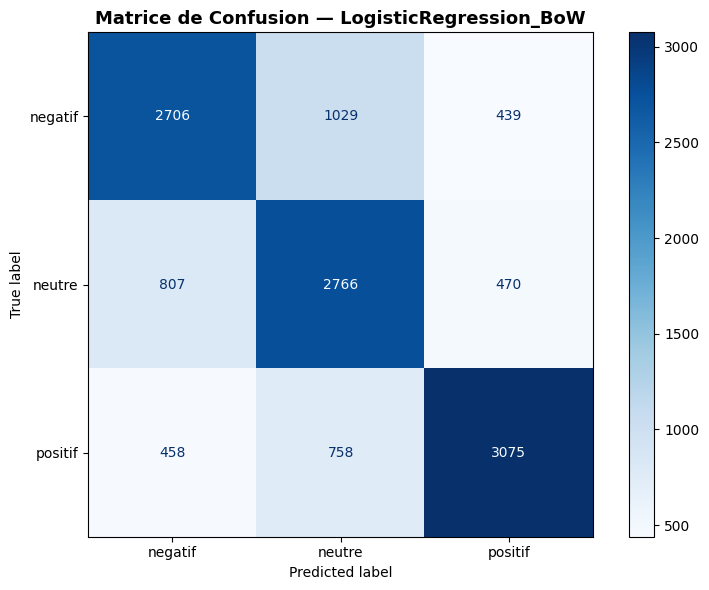

💾 Modèle sauvegardé : model_LogisticRegression_BoW.joblib


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'LogisticRegression_BoW' loggé

🔍 LR + TFIDF — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

   Meilleurs params : {'solver': 'saga', 'max_iter': 1000, 'C': 1.0}

🚀 LogisticRegression_TFIDF
   Hyperparamètres : {'solver': 'saga', 'max_iter': 1000, 'C': 1.0}
   Val  Accuracy  : 0.6847
   Val  F1 Macro  : 0.6848
   Test Accuracy  : 0.6873
   Test F1 Macro  : 0.6874

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.66      0.69      0.67      4174
      neutre       0.63      0.65      0.64      4043
     positif       0.78      0.72      0.75      4291

    accuracy                           0.69     12508
   macro avg       0.69      0.69      0.69     12508
weighted avg       0.69      0.69      0.69     12508



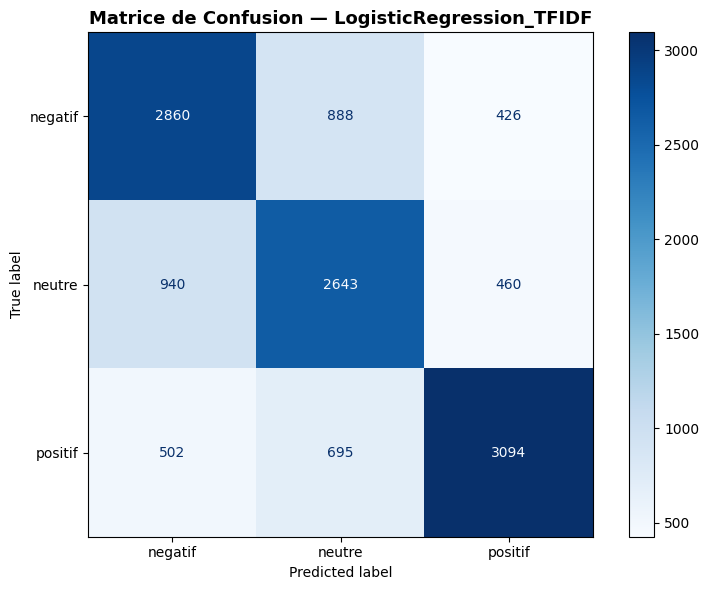

💾 Modèle sauvegardé : model_LogisticRegression_TFIDF.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'LogisticRegression_TFIDF' loggé

🔍 LR + Emb — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

   Meilleurs params : {'solver': 'saga', 'max_iter': 500, 'C': 10.0}

🚀 LogisticRegression_Emb
   Hyperparamètres : {'solver': 'saga', 'max_iter': 500, 'C': 10.0}
   Val  Accuracy  : 0.5901
   Val  F1 Macro  : 0.5885
   Test Accuracy  : 0.5881
   Test F1 Macro  : 0.5862

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.57      0.60      0.58      4174
      neutre       0.55      0.51      0.53      4043
     positif       0.65      0.65      0.65      4291

    accuracy                           0.59     12508
   macro avg       0.59      0.59      0.59     12508
weighted avg       0.59      0.59      0.59     12508



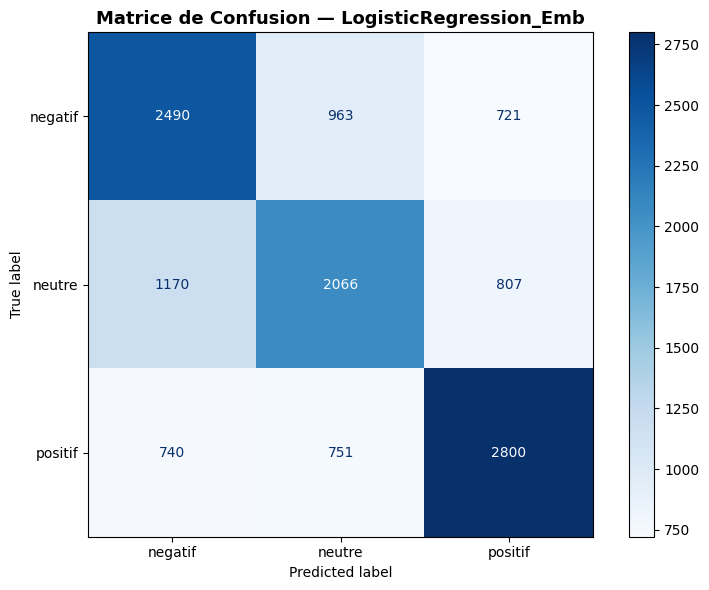

💾 Modèle sauvegardé : model_LogisticRegression_Emb.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'LogisticRegression_Emb' loggé


In [17]:
print("\n" + "="*60)
print("🔵 LOGISTIC REGRESSION")
print("="*60)

lr_param_grid = {
    'C':        [0.01, 0.1, 1.0, 5.0, 10.0],
    'solver':   ['lbfgs', 'saga'],
    'max_iter': [500, 1000]
}

for feat_name, X_tr, X_v, X_te in [
    ("BoW",   X_train_bow,   X_val_bow,   X_test_bow),
    ("TFIDF", X_train_tfidf, X_val_tfidf, X_test_tfidf),
    ("Emb",   X_train_emb,   X_val_emb,   X_test_emb),
]:
    print(f"\n🔍 LR + {feat_name} — Recherche hyperparamètres...")
    search = RandomizedSearchCV(
        LogisticRegression(random_state=SEED, multi_class='multinomial'),
        lr_param_grid, n_iter=10, cv=3,
        scoring='f1_macro', random_state=SEED, n_jobs=2, verbose=0
    )
    search.fit(X_tr, y_train)
    best_p = search.best_params_
    print(f"   Meilleurs params : {best_p}")

    best_model = LogisticRegression(
        **best_p, random_state=SEED, multi_class='multinomial'
    )
    _, metrics = train_and_evaluate(
        best_model, "LogisticRegression", feat_name,
        X_tr, y_train, X_v, y_val, X_te, y_test, le, best_p
    )
    save_result("LogisticRegression", feat_name, metrics)

Naive Bayes


🟢 NAIVE BAYES

🔍 NaiveBayes + BoW — Recherche hyperparamètres...
   Meilleurs params : {'alpha': 0.5}

🚀 NaiveBayes_BoW
   Hyperparamètres : {'alpha': 0.5}
   Val  Accuracy  : 0.6621
   Val  F1 Macro  : 0.6579
   Test Accuracy  : 0.6665
   Test F1 Macro  : 0.6622

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.64      0.69      0.66      4174
      neutre       0.65      0.54      0.59      4043
     positif       0.70      0.76      0.73      4291

    accuracy                           0.67     12508
   macro avg       0.66      0.66      0.66     12508
weighted avg       0.67      0.67      0.66     12508



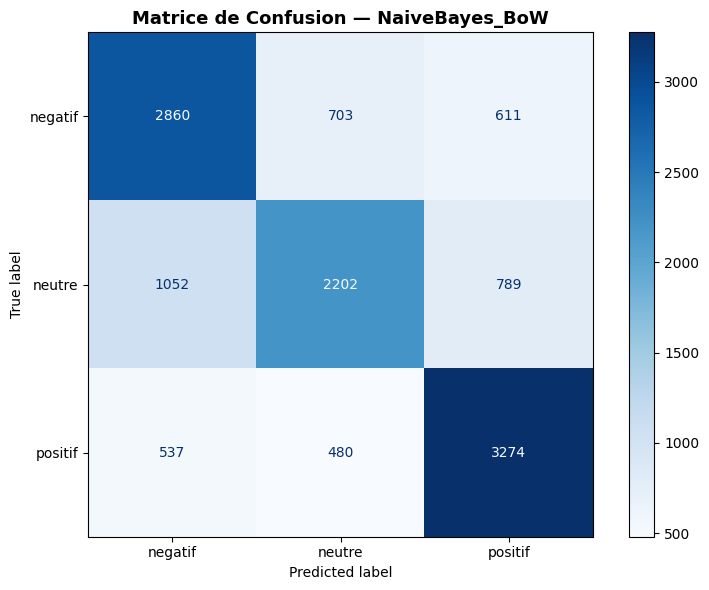

💾 Modèle sauvegardé : model_NaiveBayes_BoW.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'NaiveBayes_BoW' loggé

🔍 NaiveBayes + TFIDF — Recherche hyperparamètres...
   Meilleurs params : {'alpha': 0.5}

🚀 NaiveBayes_TFIDF
   Hyperparamètres : {'alpha': 0.5}
   Val  Accuracy  : 0.6688
   Val  F1 Macro  : 0.6650
   Test Accuracy  : 0.6732
   Test F1 Macro  : 0.6694

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.65      0.71      0.67      4174
      neutre       0.65      0.55      0.60      4043
     positif       0.72      0.75      0.73      4291

    accuracy                           0.67     12508
   macro avg       0.67      0.67      0.67     12508
weighted avg       0.67      0.67      0.67     12508



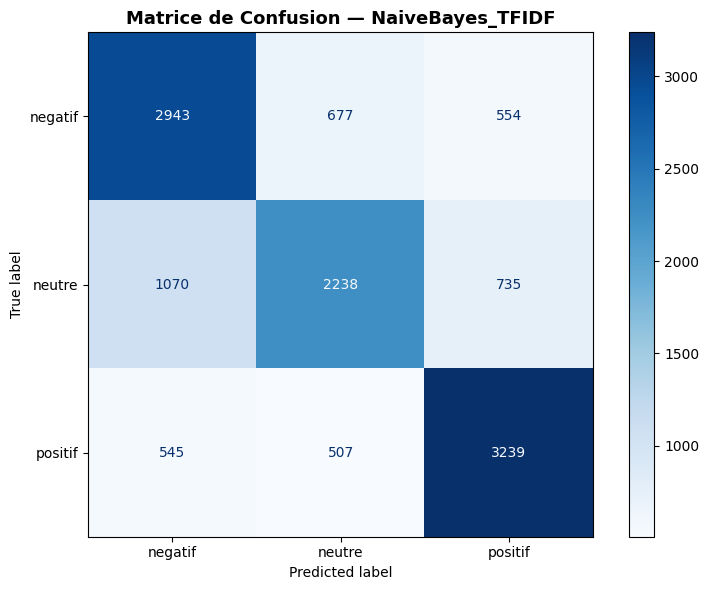

💾 Modèle sauvegardé : model_NaiveBayes_TFIDF.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'NaiveBayes_TFIDF' loggé


In [18]:
print("\n" + "="*60)
print("🟢 NAIVE BAYES")
print("="*60)

nb_param_grid = {'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0]}

for feat_name, X_tr, X_v, X_te in [
    ("BoW",   X_train_bow,   X_val_bow,   X_test_bow),
    ("TFIDF", X_train_tfidf, X_val_tfidf, X_test_tfidf),
]:
    print(f"\n🔍 NaiveBayes + {feat_name} — Recherche hyperparamètres...")
    search = GridSearchCV(
        MultinomialNB(), nb_param_grid,
        cv=3, scoring='f1_macro', n_jobs=2
    )
    search.fit(X_tr, y_train)
    best_p = search.best_params_
    print(f"   Meilleurs params : {best_p}")

    best_model = MultinomialNB(**best_p)
    _, metrics = train_and_evaluate(
        best_model, "NaiveBayes", feat_name,
        X_tr, y_train, X_v, y_val, X_te, y_test, le, best_p
    )
    save_result("NaiveBayes", feat_name, metrics)

SVM


🔴 SVM — LinearSVC

🔍 SVM + BoW — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

   Meilleurs params : {'max_iter': 3000, 'C': 0.1}

🚀 SVM_LinearSVC_BoW
   Hyperparamètres : {'max_iter': 3000, 'C': 0.1}
   Val  Accuracy  : 0.6758
   Val  F1 Macro  : 0.6761
   Test Accuracy  : 0.6792
   Test F1 Macro  : 0.6793

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.68      0.63      0.66      4174
      neutre       0.60      0.68      0.64      4043
     positif       0.76      0.72      0.74      4291

    accuracy                           0.68     12508
   macro avg       0.68      0.68      0.68     12508
weighted avg       0.68      0.68      0.68     12508



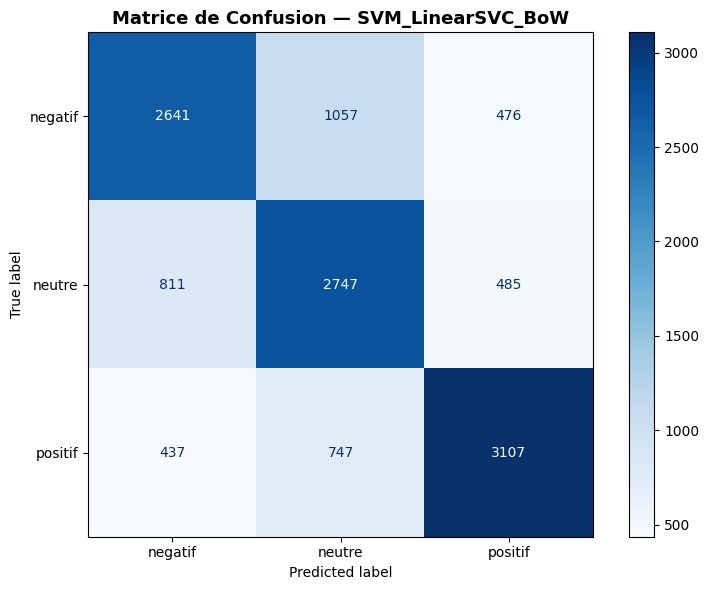

💾 Modèle sauvegardé : model_SVM_LinearSVC_BoW.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'SVM_LinearSVC_BoW' loggé

🔍 SVM + TFIDF — Recherche hyperparamètres...
   Meilleurs params : {'max_iter': 3000, 'C': 0.1}

🚀 SVM_LinearSVC_TFIDF
   Hyperparamètres : {'max_iter': 3000, 'C': 0.1}
   Val  Accuracy  : 0.6845
   Val  F1 Macro  : 0.6843
   Test Accuracy  : 0.6879
   Test F1 Macro  : 0.6877

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.67      0.69      0.68      4174
      neutre       0.63      0.64      0.64      4043
     positif       0.77      0.72      0.75      4291

    accuracy                           0.69     12508
   macro avg       0.69      0.69      0.69     12508
weighted avg       0.69      0.69      0.69     12508



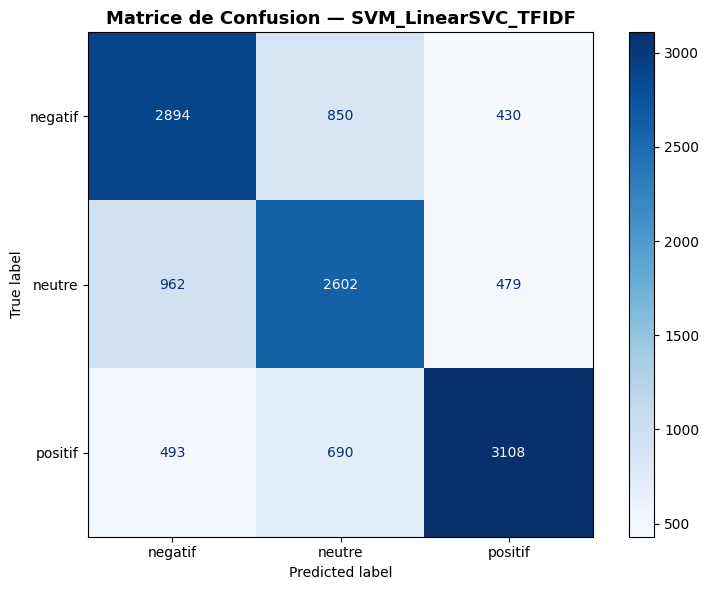

💾 Modèle sauvegardé : model_SVM_LinearSVC_TFIDF.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'SVM_LinearSVC_TFIDF' loggé

🔍 SVM + Emb — Recherche hyperparamètres...
   Meilleurs params : {'max_iter': 2000, 'C': 10.0}

🚀 SVM_LinearSVC_Emb
   Hyperparamètres : {'max_iter': 2000, 'C': 10.0}
   Val  Accuracy  : 0.5901
   Val  F1 Macro  : 0.5879
   Test Accuracy  : 0.5870
   Test F1 Macro  : 0.5842

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.57      0.60      0.58      4174
      neutre       0.55      0.49      0.52      4043
     positif       0.63      0.66      0.65      4291

    accuracy                           0.59     12508
   macro avg       0.58      0.59      0.58     12508
weighted avg       0.59      0.59      0.59     12508



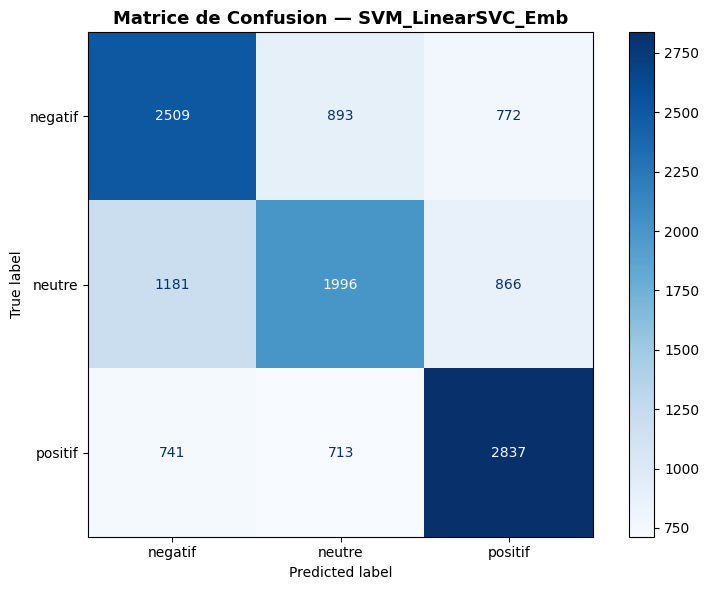

💾 Modèle sauvegardé : model_SVM_LinearSVC_Emb.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'SVM_LinearSVC_Emb' loggé


In [19]:
print("\n" + "="*60)
print("🔴 SVM — LinearSVC")
print("="*60)

svm_param_grid = {
    'C':        [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
    'max_iter': [1000, 2000, 3000]
}

for feat_name, X_tr, X_v, X_te in [
    ("BoW",   X_train_bow,   X_val_bow,   X_test_bow),
    ("TFIDF", X_train_tfidf, X_val_tfidf, X_test_tfidf),
    ("Emb",   X_train_emb,   X_val_emb,   X_test_emb),
]:
    print(f"\n🔍 SVM + {feat_name} — Recherche hyperparamètres...")
    search = RandomizedSearchCV(
        LinearSVC(random_state=SEED),
        svm_param_grid, n_iter=8, cv=3,
        scoring='f1_macro', random_state=SEED, n_jobs=2
    )
    search.fit(X_tr, y_train)
    best_p = search.best_params_
    print(f"   Meilleurs params : {best_p}")

    best_model = LinearSVC(**best_p, random_state=SEED, dual=False)
    _, metrics = train_and_evaluate(
        best_model, "SVM_LinearSVC", feat_name,
        X_tr, y_train, X_v, y_val, X_te, y_test, le, best_p
    )
    save_result("SVM_LinearSVC", feat_name, metrics)

Random Forest


🟠 RANDOM FOREST

🔍 RandomForest + BoW — Recherche hyperparamètres...
   Meilleurs params : {'n_estimators': 200, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}

🚀 RandomForest_BoW
   Hyperparamètres : {'n_estimators': 200, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}
   Val  Accuracy  : 0.6421
   Val  F1 Macro  : 0.6410
   Test Accuracy  : 0.6409
   Test F1 Macro  : 0.6397

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.63      0.60      0.62      4174
      neutre       0.58      0.61      0.60      4043
     positif       0.70      0.71      0.71      4291

    accuracy                           0.64     12508
   macro avg       0.64      0.64      0.64     12508
weighted avg       0.64      0.64      0.64     12508



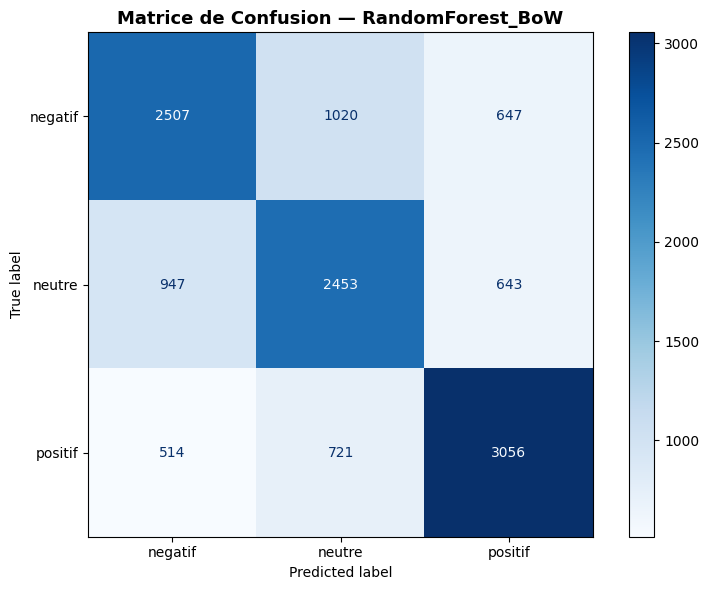

💾 Modèle sauvegardé : model_RandomForest_BoW.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'RandomForest_BoW' loggé

🔍 RandomForest + TFIDF — Recherche hyperparamètres...
   Meilleurs params : {'n_estimators': 200, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}

🚀 RandomForest_TFIDF
   Hyperparamètres : {'n_estimators': 200, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}
   Val  Accuracy  : 0.6420
   Val  F1 Macro  : 0.6412
   Test Accuracy  : 0.6423
   Test F1 Macro  : 0.6416

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.63      0.63      0.63      4174
      neutre       0.58      0.60      0.59      4043
     positif       0.71      0.70      0.71      4291

    accuracy                           0.64     12508
   macro avg       0.64      0.64      0.64     12508
weighted avg       0.64      0.64      0.64     12508



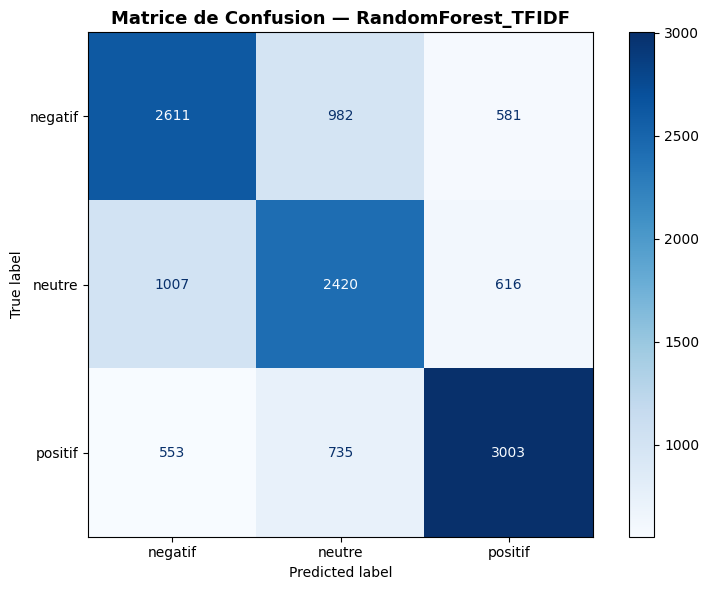

💾 Modèle sauvegardé : model_RandomForest_TFIDF.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'RandomForest_TFIDF' loggé

🔍 RandomForest + Emb — Recherche hyperparamètres...
   Meilleurs params : {'n_estimators': 300, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 20}

🚀 RandomForest_Emb
   Hyperparamètres : {'n_estimators': 300, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 20}
   Val  Accuracy  : 0.5909
   Val  F1 Macro  : 0.5883
   Test Accuracy  : 0.5946
   Test F1 Macro  : 0.5924

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.57      0.63      0.60      4174
      neutre       0.58      0.51      0.54      4043
     positif       0.63      0.64      0.64      4291

    accuracy                           0.59     12508
   macro avg       0.59      0.59      0.59     12508
weighted avg       0.59      0.59      0.59     12508



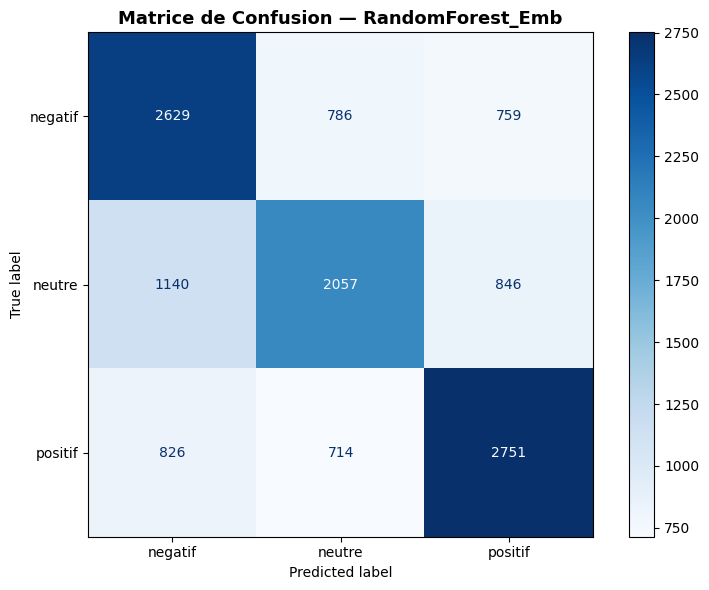

💾 Modèle sauvegardé : model_RandomForest_Emb.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'RandomForest_Emb' loggé


In [20]:
print("\n" + "="*60)
print("🟠 RANDOM FOREST")
print("="*60)

rf_param_grid = {
    'n_estimators':    [100, 200, 300],
    'max_depth':       [None, 10, 20, 30],
    'min_samples_split': [2, 5],
    'max_features':    ['sqrt', 'log2']
}

for feat_name, X_tr, X_v, X_te in [
    ("BoW",   X_train_bow,   X_val_bow,   X_test_bow),
    ("TFIDF", X_train_tfidf, X_val_tfidf, X_test_tfidf),
    ("Emb",   X_train_emb,   X_val_emb,   X_test_emb),
]:
    print(f"\n🔍 RandomForest + {feat_name} — Recherche hyperparamètres...")
    search = RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED),
        rf_param_grid, n_iter=10, cv=3,
        scoring='f1_macro', random_state=SEED, n_jobs=2
    )
    search.fit(X_tr, y_train)
    best_p = search.best_params_
    print(f"   Meilleurs params : {best_p}")

    best_model = RandomForestClassifier(**best_p, random_state=SEED)
    _, metrics = train_and_evaluate(
        best_model, "RandomForest", feat_name,
        X_tr, y_train, X_v, y_val, X_te, y_test, le, best_p
    )
    save_result("RandomForest", feat_name, metrics)

LightGBM


🟡 LIGHTGBM

🔍 LightGBM + BoW — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

   Meilleurs params : {'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 300, 'max_depth': -1, 'learning_rate': 0.2}

🚀 LightGBM_BoW
   Hyperparamètres : {'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 300, 'max_depth': -1, 'learning_rate': 0.2}
   Val  Accuracy  : 0.6540
   Val  F1 Macro  : 0.6551
   Test Accuracy  : 0.6541
   Test F1 Macro  : 0.6549

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.65      0.61      0.63      4174
      neutre       0.57      0.68      0.62      4043
     positif       0.76      0.67      0.71      4291

    accuracy                           0.65     12508
   macro avg       0.66      0.65      0.65     12508
weighted avg       0.66      0.65      0.66     12508



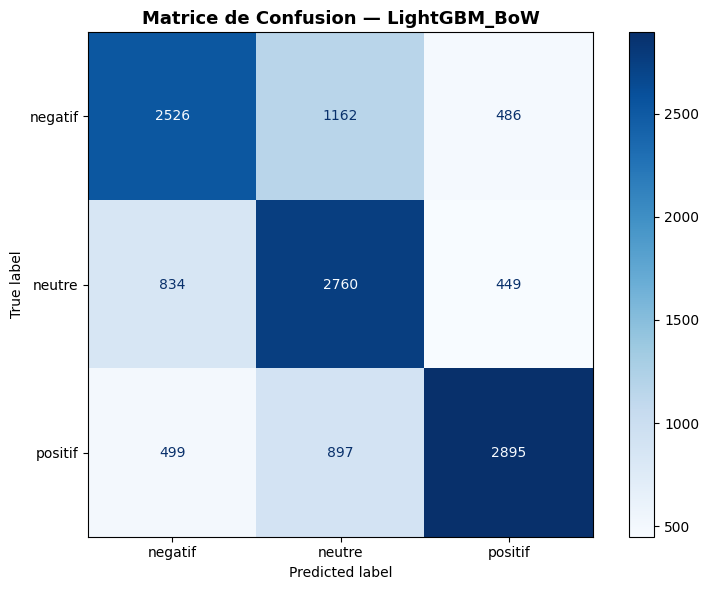

💾 Modèle sauvegardé : model_LightGBM_BoW.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'LightGBM_BoW' loggé

🔍 LightGBM + TFIDF — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

   Meilleurs params : {'subsample': 0.7, 'num_leaves': 31, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.2}

🚀 LightGBM_TFIDF
   Hyperparamètres : {'subsample': 0.7, 'num_leaves': 31, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.2}
   Val  Accuracy  : 0.6562
   Val  F1 Macro  : 0.6574
   Test Accuracy  : 0.6525
   Test F1 Macro  : 0.6536

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.65      0.61      0.63      4174
      neutre       0.57      0.67      0.62      4043
     positif       0.76      0.67      0.71      4291

    accuracy                           0.65     12508
   macro avg       0.66      0.65      0.65     12508
weighted avg       0.66      0.65      0.65     12508



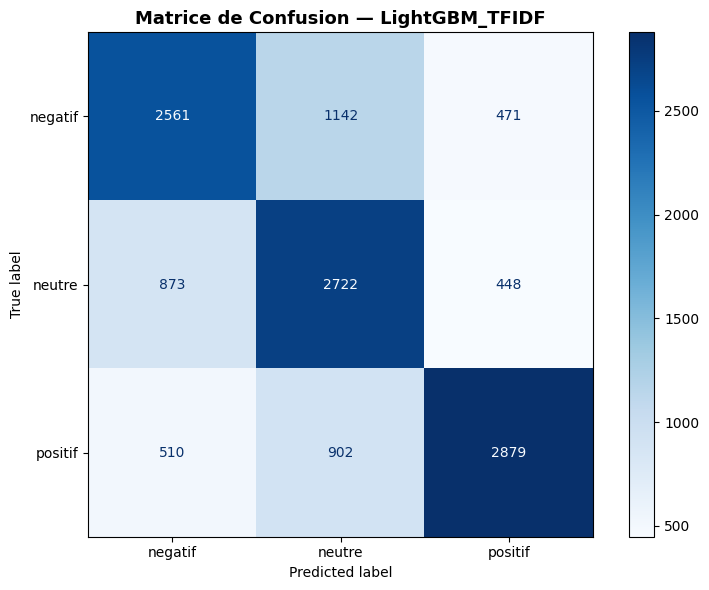

💾 Modèle sauvegardé : model_LightGBM_TFIDF.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'LightGBM_TFIDF' loggé

🔍 LightGBM + Emb — Recherche hyperparamètres...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

   Meilleurs params : {'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.05}

🚀 LightGBM_Emb
   Hyperparamètres : {'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.05}
   Val  Accuracy  : 0.6163
   Val  F1 Macro  : 0.6155
   Test Accuracy  : 0.6205
   Test F1 Macro  : 0.6195

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.60      0.64      0.62      4174
      neutre       0.59      0.56      0.57      4043
     positif       0.67      0.66      0.66      4291

    accuracy                           0.62     12508
   macro avg       0.62      0.62      0.62     12508
weighted avg       0.62      0.62      0.62     12508



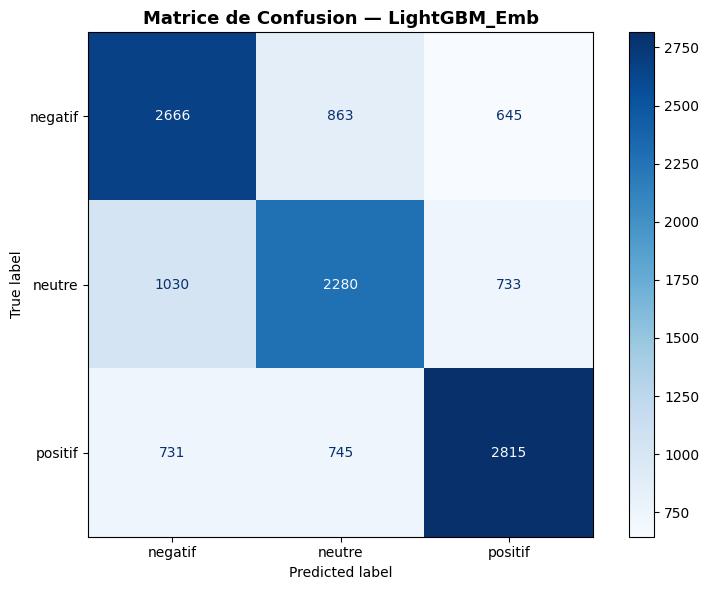

💾 Modèle sauvegardé : model_LightGBM_Emb.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'LightGBM_Emb' loggé


In [22]:
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV

print("\n" + "="*60)
print("🟡 LIGHTGBM")
print("="*60)

lgb_param_grid = {
    'n_estimators':  [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth':     [5, 10, 15, -1],
    'num_leaves':    [31, 63, 127],
    'subsample':     [0.7, 0.8, 1.0]
}

for feat_name, X_tr, X_v, X_te in [
    ("BoW",   X_train_bow,   X_val_bow,   X_test_bow),
    ("TFIDF", X_train_tfidf, X_val_tfidf, X_test_tfidf),
    ("Emb",   X_train_emb,   X_val_emb,   X_test_emb),
]:
    print(f"\n🔍 LightGBM + {feat_name} — Recherche hyperparamètres...")
    
    # ✅ Conversion en float32 pour LightGBM
    from scipy import sparse
    if sparse.issparse(X_tr):
        X_tr_lgb = X_tr.astype(np.float32)
        X_v_lgb  = X_v.astype(np.float32)
        X_te_lgb = X_te.astype(np.float32)
    else:
        X_tr_lgb = X_tr.astype(np.float32)
        X_v_lgb  = X_v.astype(np.float32)
        X_te_lgb = X_te.astype(np.float32)
    
    search = RandomizedSearchCV(
        lgb.LGBMClassifier(random_state=SEED, verbose=-1),
        lgb_param_grid, n_iter=10, cv=3,
        scoring='f1_macro', random_state=SEED, n_jobs=2
    )
    search.fit(X_tr_lgb, y_train)
    best_p = search.best_params_
    print(f"   Meilleurs params : {best_p}")

    best_model = lgb.LGBMClassifier(**best_p, random_state=SEED, verbose=-1)
    _, metrics = train_and_evaluate(
        best_model, "LightGBM", feat_name,
        X_tr_lgb, y_train, X_v_lgb, y_val, X_te_lgb, y_test, le, best_p
    )
    save_result("LightGBM", feat_name, metrics)

XGBoost


⚡ XGBOOST — PIPELINE COMPLÈTE (SÉCURISÉE)

🔍 XGBoost + BoW — Recherche hyperparamètres...
   Meilleurs params : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

🚀 XGBoost_BoW
   Hyperparamètres : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
   Val  Accuracy  : 0.5874
   Val  F1 Macro  : 0.5876
   Test Accuracy  : 0.5906
   Test F1 Macro  : 0.5910

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.62      0.49      0.55      4174
      neutre       0.49      0.74      0.59      4043
     positif       0.76      0.54      0.63      4291

    accuracy                           0.59     12508
   macro avg       0.62      0.59      0.59     12508
weighted avg       0.63      0.59      0.59     12508



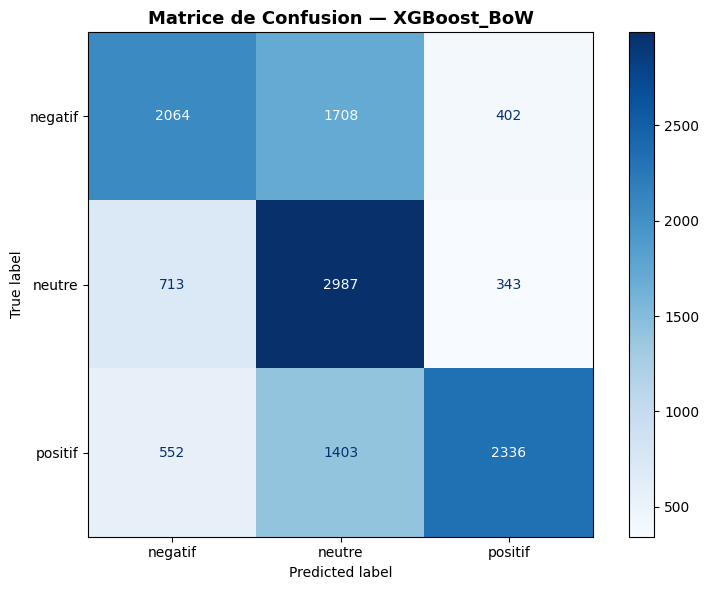

💾 Modèle sauvegardé : model_XGBoost_BoW.joblib


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'XGBoost_BoW' loggé
   ✅ RAM libérée après BoW

🔍 XGBoost + TFIDF — Recherche hyperparamètres...
   Meilleurs params : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

🚀 XGBoost_TFIDF
   Hyperparamètres : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
   Val  Accuracy  : 0.5897
   Val  F1 Macro  : 0.5899
   Test Accuracy  : 0.5919
   Test F1 Macro  : 0.5924

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.62      0.50      0.55      4174
      neutre       0.49      0.74      0.59      4043
     positif       0.76      0.54      0.63      4291

    accuracy                           0.59     12508
   macro avg       0.62      0.59      0.59     12508
weighted avg       0.63      0.59      0.59     12508



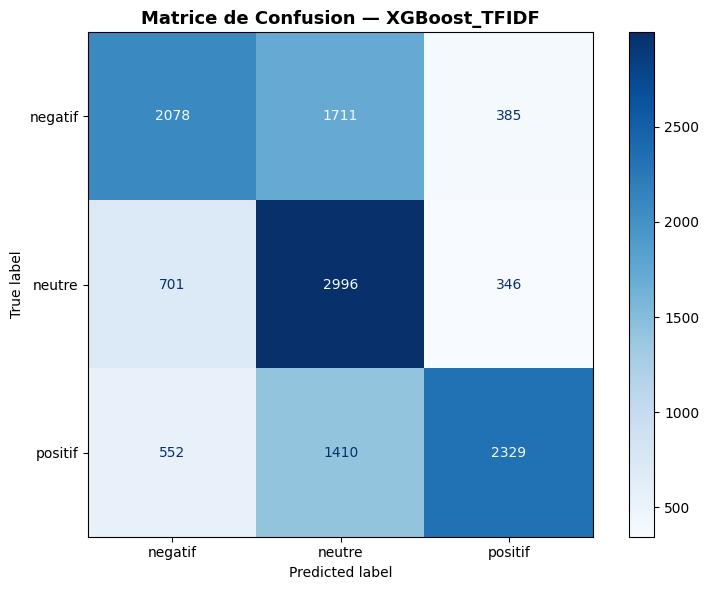

💾 Modèle sauvegardé : model_XGBoost_TFIDF.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'XGBoost_TFIDF' loggé
   ✅ RAM libérée après TFIDF

🔍 XGBoost + Emb — Recherche hyperparamètres...
   Meilleurs params : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

🚀 XGBoost_Emb
   Hyperparamètres : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
   Val  Accuracy  : 0.6229
   Val  F1 Macro  : 0.6217
   Test Accuracy  : 0.6231
   Test F1 Macro  : 0.6219

📋 Rapport détaillé (Test) :
              precision    recall  f1-score   support

     negatif       0.60      0.64      0.62      4174
      neutre       0.59      0.56      0.58      4043
     positif       0.67      0.66      0.67      4291

    accuracy                           0.62     12508
   macro avg       0.62      0.62      0.62     12508
weighted avg       0.62      0.62      0.62     12508



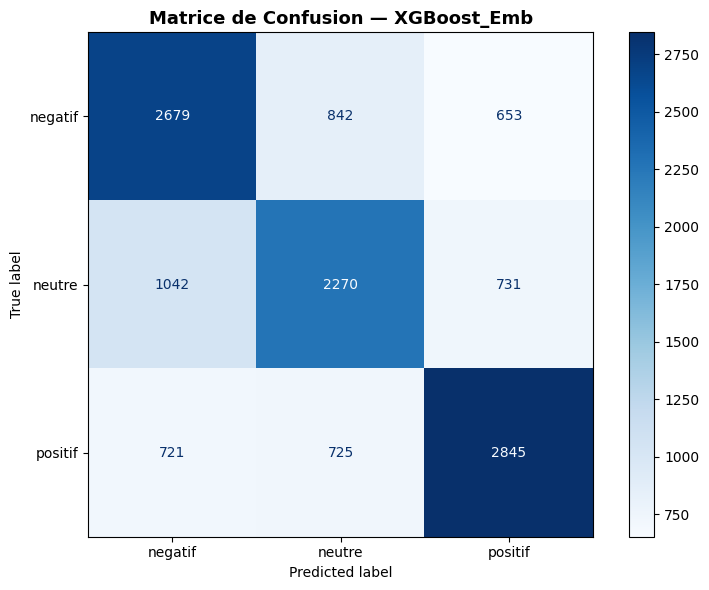

💾 Modèle sauvegardé : model_XGBoost_Emb.joblib


test_accuracy,▁
test_f1_macro,▁
test_f1_negatif,▁
test_f1_neutre,▁
test_f1_positif,▁
test_f1_weighted,▁
test_precision_macro,▁
test_precision_negatif,▁
test_precision_neutre,▁
test_precision_positif,▁
+18,...


   ✅ W&B run 'XGBoost_Emb' loggé
   ✅ RAM libérée après Emb

✅ XGBOOST TERMINÉ POUR TOUTES LES REPRÉSENTATIONS !


In [16]:
import xgboost as xgb
import numpy as np
import gc
from scipy import sparse
from sklearn.model_selection import RandomizedSearchCV

print("\n" + "="*60)
print("⚡ XGBOOST — PIPELINE COMPLÈTE (SÉCURISÉE)")
print("="*60)

# Grille de paramètres optimisée pour la rapidité
xgb_param_grid = {
    'n_estimators':     [100, 200],
    'learning_rate':    [0.05, 0.1],
    'max_depth':        [4, 6],
    'subsample':        [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# On traite les 3 représentations
for feat_name, X_tr, X_v, X_te in [
    ("BoW",   X_train_bow,   X_val_bow,   X_test_bow),
    ("TFIDF", X_train_tfidf, X_val_tfidf, X_test_tfidf),
    ("Emb",   X_train_emb,   X_val_emb,   X_test_emb),
]:
    print(f"\n🔍 XGBoost + {feat_name} — Recherche hyperparamètres...")

    # Forcer le nettoyage de la RAM avant de charger les données
    gc.collect()

    # 🚨 PROTECTION RAM : On change le type sans utiliser .toarray()
    # XGBoost gère nativement les matrices creuses (BoW/TF-IDF) et denses (Emb)
    X_tr_d = X_tr.astype(np.float32)
    X_v_d  = X_v.astype(np.float32)
    X_te_d = X_te.astype(np.float32)

    search = RandomizedSearchCV(
        xgb.XGBClassifier(
            random_state=SEED,
            eval_metric='mlogloss',
            verbosity=0,
            tree_method='hist', # Optimise l'utilisation de la mémoire
            n_jobs=1            # Évite de dupliquer la RAM pendant la recherche
        ),
        xgb_param_grid,
        n_iter=5, # 5 essais par représentation pour rester rapide
        cv=3,
        scoring='f1_macro',
        random_state=SEED,
        n_jobs=1
    )
    
    search.fit(X_tr_d, y_train)
    best_p = search.best_params_
    print(f"   Meilleurs params : {best_p}")

    # Entraînement final avec les meilleurs paramètres
    best_model = xgb.XGBClassifier(
        **best_p,
        random_state=SEED,
        eval_metric='mlogloss',
        verbosity=0,
        tree_method='hist',
        n_jobs=-1 # Utilise toute la puissance processeur pour l'entraînement final
    )
    
    _, metrics = train_and_evaluate(
        best_model, "XGBoost", feat_name,
        X_tr_d, y_train, X_v_d, y_val, X_te_d, y_test, le, best_p
    )
    save_result("XGBoost", feat_name, metrics) # Envoi vers W&B et sauvegarde locale

    # Nettoyage strict après chaque représentation pour libérer la mémoire
    del X_tr_d, X_v_d, X_te_d
    gc.collect()
    print(f"   ✅ RAM libérée après {feat_name}")

print("\n" + "="*60)
print("✅ XGBOOST TERMINÉ POUR TOUTES LES REPRÉSENTATIONS !")
print("="*60)

----
----
----

In [22]:
import joblib
import numpy as np
from scipy import sparse
import pandas as pd
import os

# Sauvegarde splits texte
np.save("X_train.npy", X_train)
np.save("X_val.npy",   X_val)
np.save("X_test.npy",  X_test)
np.save("y_train.npy", y_train)
np.save("y_val.npy",   y_val)
np.save("y_test.npy",  y_test)

# Sauvegarde LabelEncoder
joblib.dump(le, "label_encoder.joblib")

# Sauvegarde vectorizers
joblib.dump(bow_vec,   "bow_vectorizer.joblib")
joblib.dump(tfidf_vec, "tfidf_vectorizer.joblib")

# Sauvegarde matrices features
sparse.save_npz("X_train_bow.npz",   X_train_bow)
sparse.save_npz("X_val_bow.npz",     X_val_bow)
sparse.save_npz("X_test_bow.npz",    X_test_bow)
sparse.save_npz("X_train_tfidf.npz", X_train_tfidf)
sparse.save_npz("X_val_tfidf.npz",   X_val_tfidf)
sparse.save_npz("X_test_tfidf.npz",  X_test_tfidf)

# Sauvegarde embeddings FastText
np.save("X_train_emb.npy", X_train_emb)
np.save("X_val_emb.npy",   X_val_emb)
np.save("X_test_emb.npy",  X_test_emb)

# Sauvegarde résultats déjà obtenus
pd.DataFrame(all_results).to_csv("comparaison_modeles.csv", index=False)

print("✅ TOUT EST SAUVEGARDÉ !")
print(f"   Modèles déjà faits : {len(all_results)}")
for r in all_results:
    print(f"   ✅ {r['run_name']} — F1={r['test_f1_macro']:.4f}")
print("\n😴 Tu peux éteindre le PC sans problème !")

✅ TOUT EST SAUVEGARDÉ !
   Modèles déjà faits : 11
   ✅ LogisticRegression_BoW — F1=0.6837
   ✅ LogisticRegression_TFIDF — F1=0.6874
   ✅ LogisticRegression_Emb — F1=0.5862
   ✅ NaiveBayes_BoW — F1=0.6622
   ✅ NaiveBayes_TFIDF — F1=0.6694
   ✅ SVM_LinearSVC_BoW — F1=0.6793
   ✅ SVM_LinearSVC_TFIDF — F1=0.6877
   ✅ SVM_LinearSVC_Emb — F1=0.5842
   ✅ RandomForest_BoW — F1=0.6397
   ✅ RandomForest_TFIDF — F1=0.6416
   ✅ RandomForest_Emb — F1=0.5924

😴 Tu peux éteindre le PC sans problème !


In [4]:
import joblib
import numpy as np
import json
import pandas as pd
import os
import warnings
import random
from scipy import sparse
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import lightgbm as lgb
import xgboost as xgb
import matplotlib.pyplot as plt
import wandb

# ---- Config ----
SEED = 42
WANDB_PROJECT = "darija-sentiment-analysis"
WANDB_API_KEY = "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"  # ← remplace par ta vraie clé
warnings.filterwarnings('ignore')
random.seed(SEED)
np.random.seed(SEED)
os.environ["WANDB_API_KEY"] = WANDB_API_KEY
wandb.login(key=WANDB_API_KEY, relogin=True)

# ---- Rechargement données ----
X_train = np.load("X_train.npy", allow_pickle=True)
X_val   = np.load("X_val.npy",   allow_pickle=True)
X_test  = np.load("X_test.npy",  allow_pickle=True)
y_train = np.load("y_train.npy")
y_val   = np.load("y_val.npy")
y_test  = np.load("y_test.npy")

le        = joblib.load("label_encoder.joblib")
bow_vec   = joblib.load("bow_vectorizer.joblib")
tfidf_vec = joblib.load("tfidf_vectorizer.joblib")

X_train_bow   = sparse.load_npz("X_train_bow.npz")
X_val_bow     = sparse.load_npz("X_val_bow.npz")
X_test_bow    = sparse.load_npz("X_test_bow.npz")
X_train_tfidf = sparse.load_npz("X_train_tfidf.npz")
X_val_tfidf   = sparse.load_npz("X_val_tfidf.npz")
X_test_tfidf  = sparse.load_npz("X_test_tfidf.npz")

X_train_emb = np.load("X_train_emb.npy")
X_val_emb   = np.load("X_val_emb.npy")
X_test_emb  = np.load("X_test_emb.npy")

all_results = pd.read_csv("comparaison_modeles.csv").to_dict('records')

# ---- Fonctions utilitaires ----
def evaluate_model(model, X_val, y_val, X_test, y_test, le):
    metrics = {}
    for split_name, X_s, y_s in [("val", X_val, y_val), ("test", X_test, y_test)]:
        y_pred = model.predict(X_s)
        metrics[f"{split_name}_accuracy"]        = float(accuracy_score(y_s, y_pred))
        metrics[f"{split_name}_f1_macro"]        = float(f1_score(y_s, y_pred, average='macro'))
        metrics[f"{split_name}_f1_weighted"]     = float(f1_score(y_s, y_pred, average='weighted'))
        metrics[f"{split_name}_precision_macro"] = float(precision_score(y_s, y_pred, average='macro'))
        metrics[f"{split_name}_recall_macro"]    = float(recall_score(y_s, y_pred, average='macro'))
        report = classification_report(y_s, y_pred, target_names=le.classes_, output_dict=True)
        for cls in le.classes_:
            metrics[f"{split_name}_f1_{cls}"]        = float(report[cls]['f1-score'])
            metrics[f"{split_name}_precision_{cls}"] = float(report[cls]['precision'])
            metrics[f"{split_name}_recall_{cls}"]    = float(report[cls]['recall'])
    return metrics

def plot_confusion_matrix_custom(model, X_test, y_test, le, model_name):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap='Blues')
    ax.set_title(f"Matrice de Confusion — {model_name}", fontsize=13, fontweight='bold')
    filename = f"cm_{model_name.replace(' ','_').replace('/','_')}.png"
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    plt.close()
    return filename

def log_to_wandb(run_name, config, metrics, cm_path, model_path=None):
    wandb.init(project=WANDB_PROJECT, name=run_name, config=config, reinit=True)
    wandb.log(metrics)
    wandb.log({"confusion_matrix": wandb.Image(cm_path)})
    if model_path and os.path.exists(model_path):
        artifact = wandb.Artifact(name=run_name.replace(" ", "_"), type="model")
        artifact.add_file(model_path)
        wandb.log_artifact(artifact)
    wandb.finish()
    print(f"   ✅ W&B run '{run_name}' loggé")

def train_and_evaluate(model, model_name, feature_name,
                       X_train, y_train, X_val, y_val,
                       X_test, y_test, le, hyperparams):
    run_name = f"{model_name}_{feature_name}"
    print(f"\n{'='*60}")
    print(f"🚀 {run_name}")
    print(f"   Hyperparamètres : {hyperparams}")
    print(f"{'='*60}")
    model.fit(X_train, y_train)
    metrics = evaluate_model(model, X_val, y_val, X_test, y_test, le)
    print(f"   Val  F1 Macro : {metrics['val_f1_macro']:.4f}")
    print(f"   Test F1 Macro : {metrics['test_f1_macro']:.4f}")
    y_pred_test = model.predict(X_test)
    print(classification_report(y_test, y_pred_test, target_names=le.classes_))
    cm_path    = plot_confusion_matrix_custom(model, X_test, y_test, le, run_name)
    model_path = f"model_{run_name}.joblib"
    joblib.dump(model, model_path)
    print(f"💾 Modèle sauvegardé : {model_path}")
    config = {"model_name": model_name, "feature_type": feature_name, **hyperparams}
    log_to_wandb(run_name, config, metrics, cm_path, model_path)
    return model, metrics

def save_result(model_name, feature_name, metrics):
    all_results.append({
        "run_name":         f"{model_name}_{feature_name}",
        "model":            model_name,
        "features":         feature_name,
        "val_accuracy":     metrics.get("val_accuracy", 0),
        "val_f1_macro":     metrics.get("val_f1_macro", 0),
        "test_accuracy":    metrics.get("test_accuracy", 0),
        "test_f1_macro":    metrics.get("test_f1_macro", 0),
        "test_f1_weighted": metrics.get("test_f1_weighted", 0),
        "test_precision":   metrics.get("test_precision_macro", 0),
        "test_recall":      metrics.get("test_recall_macro", 0),
    })
    # Sauvegarde automatique après chaque modèle
    pd.DataFrame(all_results).to_csv("comparaison_modeles.csv", index=False)

# ---- Vérification finale ----
print("✅ TOUT RECHARGÉ — PRÊT À CONTINUER !")
print(f"\n📊 Labels    : {le.classes_}")
print(f"📊 Train     : {len(X_train)} exemples")
print(f"📊 Val       : {len(X_val)} exemples")
print(f"📊 Test      : {len(X_test)} exemples")
print(f"📊 BoW       : {X_train_bow.shape}")
print(f"📊 TF-IDF    : {X_train_tfidf.shape}")
print(f"📊 Embeddings: {X_train_emb.shape}")
print(f"\n✅ Modèles déjà terminés ({len(all_results)}) :")
for r in all_results:
    print(f"   ✅ {r['run_name']:45s} F1={r['test_f1_macro']:.4f}")
print(f"\n🚀 Prochain : LightGBM → XGBoost → MLP → Comparaison")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


FileNotFoundError: [Errno 2] No such file or directory: 'X_train.npy'

In [1]:
import os, shutil

# Voir ce qui existe dans working
print("📁 Fichiers dans /kaggle/working :")
for f in sorted(os.listdir("/kaggle/working")):
    if f.endswith(('.npy', '.npz', '.joblib', '.csv', '.png')):
        taille = os.path.getsize(f"/kaggle/working/{f}") / (1024*1024)
        print(f"   ✅ {f:45s} {taille:.1f} MB")

# Copie tout vers outputs
OUTPUT = "/kaggle/working/outputs"
os.makedirs(OUTPUT, exist_ok=True)
for f in os.listdir("/kaggle/working"):
    if f.endswith(('.npy', '.npz', '.joblib', '.csv', '.png')):
        shutil.copy(f"/kaggle/working/{f}", f"{OUTPUT}/{f}")
        print(f"   💾 Copié : {f}")

print("\n✅ Tout copié — fais Save Version maintenant !")

📁 Fichiers dans /kaggle/working :
   ✅ X_test_emb.npy                                14.3 MB
   ✅ X_train_emb.npy                               66.8 MB
   ✅ X_val_emb.npy                                 14.3 MB
   ✅ bow_vectorizer.joblib                         0.6 MB
   ✅ cm_LightGBM_BoW.png                           0.1 MB
   ✅ cm_LightGBM_Emb.png                           0.1 MB
   ✅ cm_LightGBM_TFIDF.png                         0.0 MB
   ✅ cm_LogisticRegression_BoW.png                 0.1 MB
   ✅ cm_LogisticRegression_Emb.png                 0.1 MB
   ✅ cm_LogisticRegression_TFIDF.png               0.1 MB
   ✅ cm_NaiveBayes_BoW.png                         0.1 MB
   ✅ cm_NaiveBayes_TFIDF.png                       0.0 MB
   ✅ cm_RandomForest_BoW.png                       0.0 MB
   ✅ cm_RandomForest_Emb.png                       0.1 MB
   ✅ cm_RandomForest_TFIDF.png                     0.0 MB
   ✅ cm_SVM_LinearSVC_BoW.png                      0.0 MB
   ✅ cm_SVM_LinearSVC_Emb.png      

In [3]:
import os

print("="*50)
print("🩺 DIAGNOSTIC DE LA SESSION KAGGLE")
print("="*50)

# --- 1. TEST DE LA RAM (Mémoire Vive) ---
print("\n🧠 1. État de la RAM (Variables) :")

# On vérifie si X_train_tfidf existe en mémoire
if 'X_train_tfidf' in globals() or 'X_train_tfidf' in locals():
    print("   ✅ Les matrices (X_train_tfidf, etc.) SONT ENCORE en mémoire.")
else:
    print("   ❌ Les matrices ont DISPARU de la mémoire (Kernel redémarré).")

# On vérifie si all_results existe en mémoire
if 'all_results' in globals() or 'all_results' in locals():
    print("   ✅ La liste 'all_results' EST ENCORE en mémoire.")
else:
    print("   ❌ La liste 'all_results' a DISPARU de la mémoire.")


# --- 2. TEST DU DISQUE (Fichiers sauvegardés) ---
print("\n💾 2. État du Disque (Dossier /kaggle/working/) :")

fichiers_presents = os.listdir('/kaggle/working/')
fichiers_cles = ['sauvegarde_all_results.json', 'comparaison_modeles.csv']

for f in fichiers_cles:
    if f in fichiers_presents:
        print(f"   ✅ Le fichier '{f}' a été trouvé sur le disque.")
    else:
        print(f"   ❌ Le fichier '{f}' n'existe PAS sur le disque.")

print("\n(Autres fichiers trouvés :", [f for f in fichiers_presents if f not in fichiers_cles], ")")
print("="*50)

🩺 DIAGNOSTIC DE LA SESSION KAGGLE

🧠 1. État de la RAM (Variables) :
   ❌ Les matrices ont DISPARU de la mémoire (Kernel redémarré).
   ❌ La liste 'all_results' a DISPARU de la mémoire.

💾 2. État du Disque (Dossier /kaggle/working/) :
   ❌ Le fichier 'sauvegarde_all_results.json' n'existe PAS sur le disque.
   ❌ Le fichier 'comparaison_modeles.csv' n'existe PAS sur le disque.

(Autres fichiers trouvés : ['model_LightGBM_BoW.joblib', 'cm_LightGBM_BoW.png', 'X_val_emb.npy', 'cc.ar.300.bin', 'X_test_emb.npy', 'cm_LogisticRegression_TFIDF.png', 'cm_LightGBM_Emb.png', 'tfidf_vectorizer.joblib', 'model_NaiveBayes_BoW.joblib', 'model_LogisticRegression_TFIDF.joblib', 'cm_NaiveBayes_BoW.png', 'model_SVM_LinearSVC_TFIDF.joblib', 'model_LightGBM_Emb.joblib', 'test_indices.npy', 'cm_LogisticRegression_BoW.png', 'model_SVM_LinearSVC_Emb.joblib', 'model_SVM_LinearSVC_BoW.joblib', 'model_RandomForest_TFIDF.joblib', 'cm_SVM_LinearSVC_BoW.png', 'bow_vectorizer.joblib', 'cm_RandomForest_Emb.png', 'X_t

In [6]:
import os

print("="*60)
print("🔍 INVENTAIRE RAPIDE DE TES FICHIERS KAGGLE")
print("="*60)

# On regarde dans le dossier principal de Kaggle
dossier = '/kaggle/working'
fichiers = os.listdir(dossier)

# S'il n'y a pas de fichiers
if not fichiers:
    print("Le dossier est vide !")
else:
    for f in fichiers:
        # On calcule le chemin complet pour avoir la taille
        chemin_complet = os.path.join(dossier, f)
        
        # On vérifie que c'est bien un fichier (et pas un sous-dossier)
        if os.path.isfile(chemin_complet):
            taille_mb = os.path.getsize(chemin_complet) / (1024 * 1024)
            ext = os.path.splitext(f)[1].lower() # On récupère l'extension (.joblib, .png, etc.)
            
            # On ajoute un petit commentaire pour t'aider à comprendre
            type_fichier = ""
            if ext == '.joblib':
                type_fichier = "🧠 Modèle ou Vectoriseur (Important)"
            elif ext == '.png':
                type_fichier = "📊 Graphique (Pour le rapport)"
            elif ext in ['.csv', '.json']:
                type_fichier = "📝 Fichier de résultats"
            elif ext in ['.npy', '.npz']:
                type_fichier = "🔢 Matrice de données (Lourd)"
            elif ext == '.bin':
                type_fichier = "📚 Dictionnaire d'Embedding (Très Lourd !)"
            else:
                type_fichier = "Autre fichier"
                
            print(f"📄 {f:40s} | {taille_mb:6.1f} MB | {type_fichier}")

print("="*60)
print("Fin de l'inventaire.")

🔍 INVENTAIRE RAPIDE DE TES FICHIERS KAGGLE
📄 model_LightGBM_BoW.joblib                |    3.5 MB | 🧠 Modèle ou Vectoriseur (Important)
📄 cm_LightGBM_BoW.png                      |    0.1 MB | 📊 Graphique (Pour le rapport)
📄 X_val_emb.npy                            |   14.3 MB | 🔢 Matrice de données (Lourd)
📄 cc.ar.300.bin                            | 6911.3 MB | 📚 Dictionnaire d'Embedding (Très Lourd !)
📄 X_test_emb.npy                           |   14.3 MB | 🔢 Matrice de données (Lourd)
📄 cm_LogisticRegression_TFIDF.png          |    0.1 MB | 📊 Graphique (Pour le rapport)
📄 cm_LightGBM_Emb.png                      |    0.1 MB | 📊 Graphique (Pour le rapport)
📄 tfidf_vectorizer.joblib                  |    0.8 MB | 🧠 Modèle ou Vectoriseur (Important)
📄 model_NaiveBayes_BoW.joblib              |    0.9 MB | 🧠 Modèle ou Vectoriseur (Important)
📄 model_LogisticRegression_TFIDF.joblib    |    0.5 MB | 🧠 Modèle ou Vectoriseur (Important)
📄 cm_NaiveBayes_BoW.png                    |    0.1 M

In [7]:
import os
import zipfile
from IPython.display import FileLink, display

print("📦 Préparation de ta valise VS Code...")

zip_name = "Modeles_Darija_NLP_Complets.zip"
# La sélection stricte : modèles, vectoriseurs, images, tableaux de résultats
extensions_utiles = ('.joblib', '.png', '.csv', '.json')

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk('/kaggle/working'):
        for file in files:
            # On filtre pour ne prendre que les fichiers importants
            if file.endswith(extensions_utiles):
                file_path = os.path.join(root, file)
                arcname = os.path.relpath(file_path, '/kaggle/working')
                zipf.write(file_path, arcname)

print("✅ Valise prête ! Tous tes modèles et graphiques sont compressés.")
print("👇 Clique sur ce lien pour tout télécharger d'un coup :")
display(FileLink(zip_name))

📦 Préparation de ta valise VS Code...
✅ Valise prête ! Tous tes modèles et graphiques sont compressés.
👇 Clique sur ce lien pour tout télécharger d'un coup :


/kaggle/working/Modeles_Darija_NLP_Complets.zip

In [19]:
import os
import zipfile
from IPython.display import FileLink, display

print("📦 Mise à jour de ta valise VS Code avec XGBoost...")

zip_name = "Modeles_Darija_NLP_Complets.zip"
# On garde tout ce qui est précieux : modèles, graphiques, vectoriseurs et résultats
extensions_utiles = ('.joblib', '.png', '.csv', '.json')

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk('/kaggle/working'):
        for file in files:
            # On ignore le fichier zip lui-même pour ne pas tourner en boucle
            if file == zip_name:
                continue
                
            if file.endswith(extensions_utiles):
                file_path = os.path.join(root, file)
                # arcname permet de garder une structure propre à l'intérieur du ZIP
                arcname = os.path.relpath(file_path, '/kaggle/working')
                zipf.write(file_path, arcname)
                # On affiche un petit message pour confirmer la présence du XGBoost
                if "XGBoost" in file:
                    print(f"   ➕ Ajouté : {file}")

print("\n✅ Valise finale prête ! Tes 6 types de modèles et leurs graphiques sont compressés.")
print("👇 Clique sur ce lien pour télécharger ton archive complète :")
display(FileLink(zip_name))

📦 Mise à jour de ta valise VS Code avec XGBoost...
   ➕ Ajouté : model_XGBoost_BoW.joblib
   ➕ Ajouté : cm_XGBoost_Emb.png
   ➕ Ajouté : cm_XGBoost_BoW.png
   ➕ Ajouté : model_XGBoost_TFIDF.joblib
   ➕ Ajouté : model_XGBoost_Emb.joblib
   ➕ Ajouté : cm_XGBoost_TFIDF.png

✅ Valise finale prête ! Tes 6 types de modèles et leurs graphiques sont compressés.
👇 Clique sur ce lien pour télécharger ton archive complète :


/kaggle/working/Modeles_Darija_NLP_Complets.zip